# EDA 13: bằng chứng để gộp khoảng trống (gap) vào home/office

Tiếp nối `11_gap_stay.ipynb` và `12_home_office_windows.ipynb`. Stay dùng `h1_mean`. Notebook này hỏi: khi tính home/office, **gap có đáng tin không và nên xử lý thế nào**.

**Đáp án để chấm.** Home/office suy ra chỉ từ **giờ có GPS** (`home_gps`: nơi nhiều giờ GPS đêm 0–6h nhất; `office_gps`: nơi nhiều giờ GPS thứ 2–6, 9–17h nhất). Chỉ dùng user có đủ giờ GPS ở nơi đó (`MIN_GPS_NIGHT_H`, `MIN_GPS_OFFICE_H`). **Hạn chế:** GPS ban đêm là lúc máy bật, thường là lúc đang thức hoặc đang đi, nên đáp án GPS là **tham chiếu**, không phải sự thật. Khi gap và GPS không khớp, chưa chắc gap sai.

| Mục | Câu hỏi | Trình bày |
|---|---|---|
| 1 | Gap chiếm bao nhiêu giờ đêm và giờ hành chính? Home/office phụ thuộc gap đến mức nào? | bảng 1, hình |
| 2 | Gap qua đêm / ban ngày có thật sự nằm ở home / office (đáp án GPS) không, theo độ dài và khoảng cách hai đầu? | bảng 2a–2c, hình |
| 3 | Bao nhiêu đêm / ngày làm việc là đủ để bỏ phiếu (A11)? | bảng, hình |

**Cách chạy.** `run_compare` (stay `h1_mean`) đọc từ cache của notebook 10, nếu chưa có thì tự tính vài phút. `run_evidence` vài phút; lưu từng user ở `data/interim/eda_stay_anchor_mean/<user>_gapev.pkl`; đổi code `gap_evidence.py` thì xoá các file đó.


> **Giai đoạn: TUNING (sau khi chia validation / test).** Chỉ đọc **nhóm validation** (`split.val_users()`). Không dùng nhóm test (D17, D19).

In [1]:
# chạy được ngay cả khi chưa chạy các mục trước
import importlib
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from preprocess import interim
from eda import stay_anchor as sa
from eda import gap_evidence as ge
from eda import stay_anchor_plots as sp
from eda import split
for m in (sa, ge, sp):
    importlib.reload(m)

USERS = None              # ví dụ ["000", "001", "002"] để chạy thử nhanh
MIN_GPS_NIGHT_H = 10      # giờ GPS đêm tối thiểu ở nơi đó để tin làm đáp án home
MIN_GPS_OFFICE_H = 20     # giờ GPS hành chính tối thiểu ở nơi đó để tin làm đáp án office

users = split.val_users()
if USERS:
    users = [u for u in users if u in set(USERS)]
sa.run_compare(users)                       # stay h1_mean; đọc từ cache nếu đã chạy notebook 10
U, G, H = ge.run_evidence(users)

home_ok = U["home_gps_hours"] >= MIN_GPS_NIGHT_H
office_ok = U["office_gps_hours"] >= MIN_GPS_OFFICE_H
G = G.merge(U[["user"]].assign(home_ok=home_ok.to_numpy(), office_ok=office_ok.to_numpy()), on="user")
G.loc[~G["home_ok"], "d_home"] = np.nan
G.loc[~G["office_ok"], "d_office"] = np.nan
print(f"{len(U)} user; đủ GPS để làm đáp án: home {home_ok.sum()}, office {office_ok.sum()}, cả hai {(home_ok & office_ok).sum()}")
print(f"{len(G):,} khoảng trống > 30 phút nằm trong stay")

115 user đã có kết quả, 0 user cần tính, 15 tiến trình
115 user đã có kết quả, 0 user cần tính, 15 tiến trình
108 user; đủ GPS để làm đáp án: home 12, office 4, cả hai 2
8,434 khoảng trống > 30 phút nằm trong stay


## 1. Gap chiếm bao nhiêu giờ đêm và giờ hành chính

Với mỗi giờ trong ngày, bao nhiêu % thời gian là gap (máy không ghi > 30 phút). Rồi theo từng user: % giờ đêm và giờ hành chính là gap, và phần giờ của home / office (tính như Li hiện nay, cộng mọi gap) đến từ gap.

Nếu phần này gần 100% thì home/office của user gần như hoàn toàn dựa vào gap, nên cách xử lý gap quyết định kết quả.

Bảng 1. Phần của gap trong giờ đêm / giờ hành chính, theo user


,số user,p10,trung vị,p90
% giờ đêm (0–6h) là gap,108.0,94.5,99.0,100.0
% giờ hành chính là gap,104.0,86.2,97.6,99.7
% giờ đêm của nơi home (đếm mọi gap) đến từ gap,98.0,23.4,98.2,100.0
% giờ hành chính của nơi office (đếm mọi gap) đến từ gap,95.0,50.7,97.1,99.8


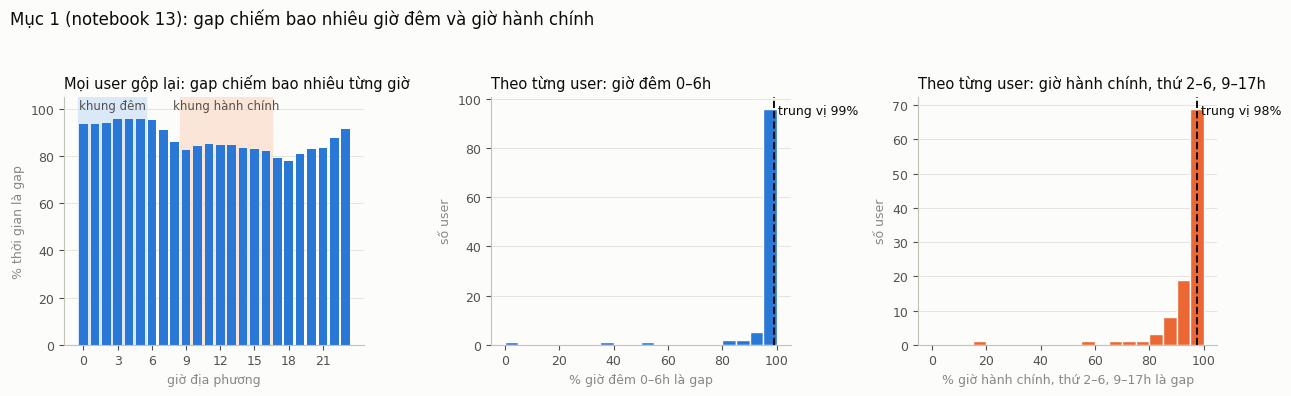

In [2]:
def phan_vi(s):
    s = s.dropna()
    return pd.Series({"số user": len(s), "p10": s.quantile(0.1), "trung vị": s.median(), "p90": s.quantile(0.9)})

bang1 = pd.DataFrame({
    "% giờ đêm (0–6h) là gap": phan_vi(100 * U["night_gap_h"] / (U["night_gap_h"] + U["night_gps_h"])),
    "% giờ hành chính là gap": phan_vi(100 * U["office_gap_h"] / (U["office_gap_h"] + U["office_gps_h"])),
    "% giờ đêm của nơi home (đếm mọi gap) đến từ gap": phan_vi(100 * U["home_gap_share"]),
    "% giờ hành chính của nơi office (đếm mọi gap) đến từ gap": phan_vi(100 * U["office_gap_share"]),
}).T
print("Bảng 1. Phần của gap trong giờ đêm / giờ hành chính, theo user")
display(bang1.round(1))
sp.gap_coverage(H, U);

## 2. Gap có ở home / office không

Với mỗi khoảng trống trong stay, lấy **hai đầu** (điểm ngay trước và ngay sau) và đo xa nhất trong hai đầu cách `home_gps` / `office_gps` bao nhiêu. "Ở nơi đó" = cả hai đầu cách tâm địa điểm ≤ 300 m (200 m bán kính stay + dư cho nhiễu GPS). Chỉ tính user đủ GPS làm đáp án.

- **28a.** Gap qua đêm, hai đầu gần nhau : bao nhiêu % ở home, theo độ dài.
- **28b.** Gap qua đêm, theo hai đầu cách nhau bao xa: hai đầu xa nhau có còn ở home không.
- **28c.** Gap ban ngày, hai đầu gần nhau: % ở office và % ở home (WFH), theo độ dài.

Mốc để coi là đáng tin: ≥ 90% ở nơi đó và đủ mẫu (cột `n`).

Bảng 2a. Gap qua đêm, hai đầu gần nhau: % ở HOME (cả hai đầu cách home ≤ 300 m)


,n,pct_ở_nơi_đó,trung_vị_m
độ dài (giờ),,,
"(2.0, 4.0]",4,25.0,8212.9
"(4.0, 8.0]",16,25.0,6868.9
"(8.0, 12.0]",189,47.1,6768.1
"(12.0, 24.0]",202,49.5,3485.6


Bảng 2b. Gap qua đêm, theo hai đầu cách nhau: % ở HOME


,n,pct_ở_nơi_đó,trung_vị_m
hai đầu cách nhau (m),,,
"(0.0, 200.0]",411,47.2,6713.9
"(200.0, 400.0]",132,56.8,268.0


Bảng 2c. Gap ban ngày, hai đầu gần nhau: % ở OFFICE (trên) và % ở HOME (dưới)


,n,pct_ở_nơi_đó,trung_vị_m
độ dài (giờ),,,
"(0.5, 1.0]",622,18.3,7612.4
"(1.0, 2.0]",377,22.3,6227.7
"(2.0, 4.0]",226,21.2,2889.8
"(4.0, 8.0]",65,30.8,4053.5
"(8.0, 12.0]",70,74.3,195.8
"(12.0, 24.0]",76,22.4,10939.9


,n,pct_ở_nơi_đó,trung_vị_m
độ dài (giờ),,,
"(0.5, 1.0]",717,16.6,8114.4
"(1.0, 2.0]",528,16.7,8029.9
"(2.0, 4.0]",331,11.2,8023.5
"(4.0, 8.0]",117,14.5,10122.7
"(8.0, 12.0]",358,8.7,5524.4
"(12.0, 24.0]",336,38.4,6761.5


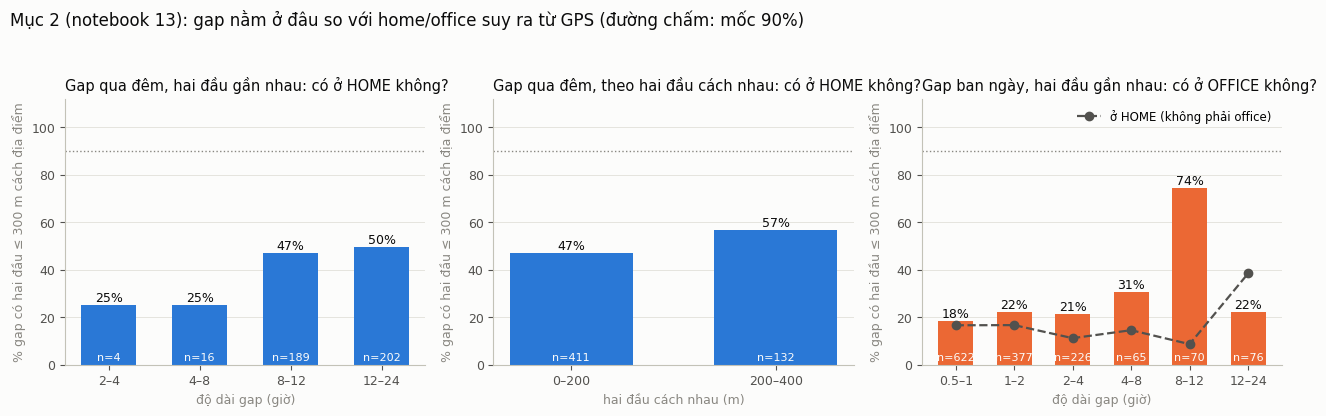

In [3]:
gan = G["end_m"] <= ge.NEAR_M
dem = G["overnight"]
ngay = ~G["overnight"]

b2a = ge.at_place_by_length(G, "home", dem & gan)
b2b = ge.at_place_by_ends(G, "home", dem)
b2c_off = ge.at_place_by_length(G, "office", ngay & gan)
b2c_home = ge.at_place_by_length(G, "home", ngay & gan)
print("Bảng 2a. Gap qua đêm, hai đầu gần nhau: % ở HOME (cả hai đầu cách home ≤ 300 m)")
display(b2a.round(1))
print("Bảng 2b. Gap qua đêm, theo hai đầu cách nhau: % ở HOME")
display(b2b.round(1))
print("Bảng 2c. Gap ban ngày, hai đầu gần nhau: % ở OFFICE (trên) và % ở HOME (dưới)")
display(b2c_off.round(1)); display(b2c_home.round(1))
sp.gap_agreement(b2a, b2b, b2c_off, b2c_home);

## 3. Bao nhiêu đêm / ngày làm việc là đủ để bỏ phiếu (A11)

**Câu hỏi:** bỏ phiếu home / office (D18, `places/home_office_conf.py`) cần ít nhất bao nhiêu đêm / ngày làm việc có phiếu thì kết quả mới lặp lại được?

**Cách đo (hai mẫu rời nhau):** với mỗi user và mỗi k, bốc ngẫu nhiên 2k phiếu từ các đêm (home) hoặc ngày làm việc (office) có phiếu, chia hai nhóm rời nhau mỗi nhóm k phiếu, bỏ phiếu riêng từng nhóm, rồi hỏi **hai nhóm có cho cùng nơi thắng không**. Lặp 200 lần, lấy trung bình theo user rồi theo nhóm user. Không có "chuẩn" trùng với mẫu, và chỉ cần user có ít nhất 2k phiếu (k = 7 cần 14 phiếu, không phải 30).

**Cách đọc mức tin cậy:** nếu mỗi nhóm trùng nơi thắng thật với xác suất q thì hai nhóm trùng nhau khoảng q². Mức 81% hai nhóm trùng nhau ứng với mỗi nhóm trùng chuẩn khoảng 90%. Mức 90% là quy ước.

**Hạn chế:** đo độ **tái lập**, không đo độ đúng, vì chưa có đáp án (A13). Khi k tăng thì số user có đủ 2k phiếu giảm và nhóm user thay đổi, nên đường "mọi user" có thể tăng vì đổi nhóm user. Vì vậy vẽ thêm **nhóm cố định** (user có ít nhất 28 phiếu, dùng được mọi k đến 14). User có hai nơi sát nhau (kể cả do gom địa điểm v1 cắt đôi một nơi) sẽ không bao giờ trùng nhau dù có nhiều phiếu.

{'home': 108, 'office': 108} user có ít nhất 2 phiếu cho k nhỏ nhất
Phép đo này phủ bao nhiêu: user cần ít nhất t phiếu (2k phiếu cho k = t / 2); nhóm validation có 115 user


số user  % user của nhóm  % tổng số phiếu
loại   điều kiện                                            
home   ≥ 6 phiếu      66.0             57.4             97.4
       ≥ 10 phiếu     49.0             42.6             93.6
       ≥ 14 phiếu     41.0             35.7             91.0
       ≥ 20 phiếu     31.0             27.0             85.6
       ≥ 28 phiếu     25.0             21.7             81.3
office ≥ 6 phiếu      54.0             47.0             96.0
       ≥ 10 phiếu     41.0             35.7             91.8
       ≥ 14 phiếu     33.0             28.7             87.6
       ≥ 20 phiếu     26.0             22.6             82.2
       ≥ 28 phiếu     18.0             15.7             74.0

Bảng 3. % hai nhóm rời nhau cho cùng nơi thắng, theo số phiếu mỗi nhóm (mức tin cậy 81%)


,home: mọi user (%),home: số user,home: nhóm cố định (%),office: mọi user (%),office: số user,office: nhóm cố định (%)
số phiếu mỗi nhóm,,,,,,
k = 3,40.8,66.0,45.3,45.3,54.0,40.9
k = 5,51.7,49.0,57.3,58.3,41.0,56.4
k = 7,58.4,41.0,62.9,65.0,33.0,65.5
k = 10,64.4,31.0,67.3,73.2,26.0,72.3
k = 14,71.0,25.0,71.0,79.0,18.0,79.0


home, mọi user dùng được: k nhỏ nhất đạt 81% và không tụt lại = None (86 user)
home, nhóm cố định (≥ 28 phiếu): k nhỏ nhất đạt 81% và không tụt lại = None (25 user)
office, mọi user dùng được: k nhỏ nhất đạt 81% và không tụt lại = 25 (8 user)
office, nhóm cố định (≥ 28 phiếu): k nhỏ nhất đạt 81% và không tụt lại = 25 (8 user)


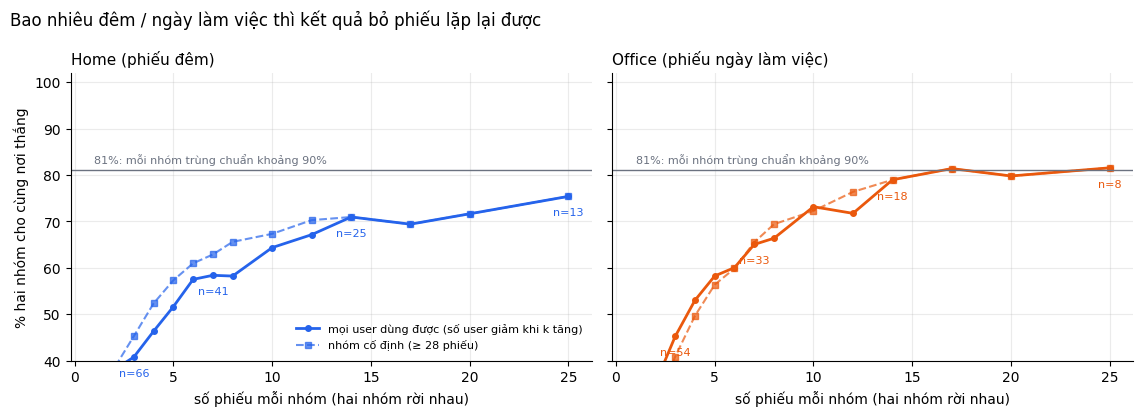

In [4]:
from eda import min_days as md
importlib.reload(md)
D29 = md.run(users)
print({k: int(D29[D29["kind"] == k]["user"].nunique()) for k in ("home", "office")}, "user có ít nhất 2 phiếu cho k nhỏ nhất")
print(f"Phép đo này phủ bao nhiêu: user cần ít nhất t phiếu (2k phiếu cho k = t / 2); nhóm validation có {len(users)} user")
display(md.coverage(D29, len(users)).round(1))
print(f"Bảng 3. % hai nhóm rời nhau cho cùng nơi thắng, theo số phiếu mỗi nhóm (mức tin cậy {100 * md.THR:.0f}%)")
display(md.table(D29).round(1))
for kind in ("home", "office"):
    for fixed in (False, True):
        k, n = md.first_k(D29, kind, fixed)
        nhom = f"nhóm cố định (≥ {md.N_FIXED} phiếu)" if fixed else "mọi user dùng được"
        print(f"{kind}, {nhom}: k nhỏ nhất đạt {100 * md.THR:.0f}% và không tụt lại = {k} ({n} user)")
md.plot(D29);

**Kết quả:** (validation 115 user) hai nhóm rời nhau, mỗi nhóm k phiếu, cho cùng nơi thắng: home 40,8% (k = 3), 51,7% (k = 5), 58,4% (k = 7), 64,4% (k = 10), 71,0% (k = 14); office 45,3%, 58,3%, 65,0%, 73,2%, 79,0%. Đường tăng đều, không có điểm gãy. Mức 81% (mỗi nhóm khoảng 90%) không đạt ở home với k nào; office chỉ đạt ở k = 25 và chỉ còn 8 user. Nhóm cố định (≥ 28 phiếu: 25 user home, 18 user office) cho cùng chiều với "mọi user" (home 45,3% → 71,0%, office 40,9% → 79,0%), nên chiều tăng không chỉ do đổi nhóm user. Số user đủ phiếu giảm nhanh: ≥ 6 phiếu có 66 user home (57,4%) và 54 user office (47,0%); ≥ 14 phiếu có 41 và 33 user.

**Quyết định:** giữ 7 phiếu tối thiểu (A11, Duy chốt 2026-11-07) là quy ước, không có điểm gãy làm căn cứ. Dưới 7 phiếu vẫn trả nơi thắng nhưng `confidence` để trống và gắn cờ `few_nights` / `few_workdays`. Hạn chế: đo độ tái lập, không đo độ đúng (A13); không mức k nào đạt 81% cho home.

## Kết luận

**Kết quả:** (validation)
- **Mục 1:** gần như toàn bộ giờ đêm và giờ hành chính là khoảng trống: trung vị theo user 99,0% giờ đêm và 97,6% giờ hành chính là gap (p10: 94,5% và 86,2%). Giờ đêm của nơi home đến từ gap có trung vị 98,2% (p10 23,4%), giờ hành chính của nơi office 97,1% (p10 50,7%). Home / office gần như hoàn toàn dựa vào gap-stay, nên cách xử lý gap quyết định kết quả.
- **Mục 2:** đáp án từ GPS chỉ có ở 12 user cho home và 4 user cho office (2 user có cả hai), nên không đủ để chấm. Gap qua đêm có hai đầu gần nhau nằm ở home chỉ 47,1% (8–12 giờ, n = 189) và 49,5% (12–24 giờ, n = 202), dưới mốc 90%; gap ban ngày ở office từ 18,3% đến 30,8% (riêng 8–12 giờ 74,3%, n = 70). Không độ dài nào đạt mốc đáng tin. Mẫu quá ít user, nên không kết luận mạnh.
- **Mục 3:** không có điểm gãy về số phiếu (xem trên).
- **Mục 4:** xem kết quả ở cuối mục 4.

**Quyết định:** không đổi cách xử lý gap vì không có đáp án để chứng minh (A12, A13); giữ gap-stay như hiện tại (max gap 24 giờ, D16) và dùng `gps_share` cùng cờ để báo mức dựa vào gap. Số phiếu tối thiểu 7 là quy ước (A11).

## 4. Confidence có dự đoán được kết quả ở giai đoạn sau không

**Câu hỏi:** user có confidence cao khi chỉ nhìn **nửa đầu** thời gian dữ liệu có giữ nguyên home / office ở **nửa sau** nhiều hơn user confidence thấp không?

**Cách đo:** chia stay của từng user thành hai nửa theo giờ đến (trung vị thời gian). Chạy bỏ phiếu (D18) riêng trên từng nửa. Confidence (%, bốc lại 200 lần, D18) lấy từ **nửa đầu**, nhóm theo mức dưới 70%, 70–90%, từ 90%. User có dưới 7 phiếu ở nửa đầu không có confidence nên không vào bảng 4 (xem 4.1). Hai kết quả "trùng" khi cùng `place_id` hoặc hai tâm cách nhau ≤ 200 m.

**Giới hạn:** đo độ **tái lập theo thời gian**, không đo độ đúng (không có đáp án, A13). User ở yên một nơi sẽ trùng dù confidence thấp vì dữ liệu ít. Mỗi nửa chỉ còn khoảng một nửa số phiếu nên nửa sau cũng thiếu dữ liệu; chỉ so trong số user có kết quả ở cả hai nửa (cột `có kết quả nửa sau` cho biết bao nhiêu). Chỉ nhóm validation; nhóm test để dành.

In [5]:
from eda import conf_holdout as ch
importlib.reload(ch)
R30 = ch.run(split.val_users())
for kind in ("home", "office"):
    g, rho, n_both = ch.summary(R30, kind)
    print(f"Bảng 4 ({kind}): confidence nửa đầu và việc giữ nguyên nơi ở nửa sau. {n_both} user có kết quả ở cả hai nửa")
    display(g.round(2))
    print(f"Tương quan hạng giữa confidence nửa đầu và trùng nơi: {rho:.2f}\n")

Bảng 4 (home): confidence nửa đầu và việc giữ nguyên nơi ở nửa sau. 40 user có kết quả ở cả hai nửa


,user có confidence nửa đầu,có kết quả nửa sau,trùng nơi (% trong số có cả hai),"confidence nửa đầu, trung bình (%)"
confidence nửa đầu,,,,
dưới 70%,15,15,20.00,50.40
70–90%,4,4,25.00,78.65
từ 90%,21,21,66.67,97.73


Tương quan hạng giữa confidence nửa đầu và trùng nơi: 0.40

Bảng 4 (office): confidence nửa đầu và việc giữ nguyên nơi ở nửa sau. 20 user có kết quả ở cả hai nửa


,user có confidence nửa đầu,có kết quả nửa sau,trùng nơi (% trong số có cả hai),"confidence nửa đầu, trung bình (%)"
confidence nửa đầu,,,,
dưới 70%,6,4,25.00,46.23
70–90%,5,5,80.00,80.02
từ 90%,14,11,81.82,98.03


Tương quan hạng giữa confidence nửa đầu và trùng nơi: 0.40



**Đọc kết quả** (số ở bảng trên): nếu tỉ lệ trùng tăng từ mức dưới 70% lên mức từ 90% và tương quan hạng dương rõ thì confidence có ý nghĩa dự đoán độ tái lập. So thêm cột trùng nơi với cột confidence trung bình: nếu confidence 95% mà chỉ trùng 60% thì con số % đang quá lạc quan. Mẫu mỗi mức chỉ vài chục user nên chênh vài điểm phần trăm chưa đáng tin; chỉ đọc các chênh lệch lớn.

**Kết quả:** home (40 user có kết quả ở cả hai nửa): user có confidence nửa đầu từ 90% giữ nguyên nơi ở nửa sau 66,7% (21 user), dưới 70% là 20,0% (15 user), mức 70–90% là 25,0% (4 user); tương quan hạng 0,40. Office (20 user): từ 90% là 81,8% (11 user), dưới 70% là 25,0% (4 user), mức 70–90% là 80,0% (5 user); tương quan hạng 0,40. Confidence cao đi cùng độ tái lập cao hơn, nhưng con số quá lạc quan: confidence trung bình nửa đầu là 97,7% (home) và 98,0% (office) trong khi chỉ 66,7% và 81,8% trùng ở nửa sau. Đây là độ chắc của quy tắc bỏ phiếu, không phải xác suất đúng (A13); mẫu mỗi mức chỉ vài chục user hoặc ít hơn.

### 4.1 Theo số phiếu thật ở nửa đầu

Cùng phép chia nửa đầu / nửa sau, nhưng nhóm theo **số phiếu thật của user ở nửa đầu** (1–3, 4–6, 7–13, từ 14) thay vì theo confidence, gồm cả user dưới 7 phiếu (không có confidence). Mỗi nhóm gồm đúng những user chỉ có chừng đó phiếu, nên không suy từ user nhiều phiếu sang user ít phiếu. Chỉ lấy user có ít nhất 7 phiếu ở nửa sau để nửa sau đủ làm chuẩn. **Hạn chế:** nửa sau cũng là một mẫu nên tỉ lệ trùng bị đo thấp hơn thực tế; mẫu mỗi nhóm nhỏ.

In [6]:
for kind in ("home", "office"):
    print(f"Bảng 4.1 ({kind}): nơi thắng nửa đầu có trùng nửa sau không, theo số phiếu thật ở nửa đầu (nửa sau ≥ 7 phiếu)")
    display(ch.summary_by_votes(R30, kind).round(1))

Bảng 4.1 (home): nơi thắng nửa đầu có trùng nửa sau không, theo số phiếu thật ở nửa đầu (nửa sau ≥ 7 phiếu)


,số user,trùng nơi (%)
số phiếu nửa đầu,,
1–3,0,NaN
4–6,4,25.0
7–13,10,40.0
từ 14,26,42.3


Bảng 4.1 (office): nơi thắng nửa đầu có trùng nửa sau không, theo số phiếu thật ở nửa đầu (nửa sau ≥ 7 phiếu)


,số user,trùng nơi (%)
số phiếu nửa đầu,,
1–3,0,NaN
4–6,2,50.0
7–13,7,57.1
từ 14,10,80.0


**Đọc kết quả** (số ở bảng trên): nếu tỉ lệ trùng tăng rõ khi số phiếu nửa đầu tăng thì số phiếu thật ảnh hưởng độ tái lập, và nhóm nào còn dưới mức mong muốn là nhóm chưa đủ phiếu. Nhóm có ít user thì chỉ đọc xu hướng, không đọc chênh vài điểm phần trăm.

**Kết quả:** home: 4–6 phiếu trùng 25,0% (4 user), 7–13 phiếu 40,0% (10 user), từ 14 phiếu 42,3% (26 user). Office: 4–6 phiếu 50,0% (2 user), 7–13 phiếu 57,1% (7 user), từ 14 phiếu 80,0% (10 user). Office tăng theo số phiếu; home tăng từ 4–6 lên 7–13 phiếu nhưng gần như phẳng từ 7 phiếu trở đi (chênh 2 điểm không đáng tin). Các nhóm nhỏ (2 đến 10 user) chỉ đọc xu hướng.

## 5. Xem kết quả bước 7 (file CSV)

Đọc file do `python -m src.places.home_office_conf` ghi ra (mặc định `reports/home_office_v1_val.csv`, chỉ nhóm validation). Mỗi dòng một user:

- `home`, `office`: `place_id` của nơi thắng (0 là nơi có tổng thời gian lớn nhất của user, xem `cluster_v1`). Trống nếu không có phiếu hoặc office trùng home.
- `n_night_votes`, `n_work_votes`: số đêm / ngày làm việc có phiếu.
- `conf_home`, `conf_office`: confidence (%), trống nếu dưới 7 phiếu.
- `flags`: các cờ, ngăn bởi `;`.

Đặt `XEM_USER` để xem một user cụ thể.

In [7]:
from places import home_office_conf as hoc
importlib.reload(hoc)

HO_CSV = ROOT / "reports" / "home_office_v1_val.csv"
XEM_USER = None           # ví dụ "010"; None = mọi user
ALL_COLS = True
        # True = hiện cả các cột báo cáo (share, margin, gps, stable)

ho = pd.read_csv(HO_CSV, dtype={"user": str})
print(f"{len(ho)} user, file {HO_CSV.name}")
print("Bảng 5a: confidence (%)")
display(hoc.conf_summary(ho))
print("Bảng 5b: số user theo cờ")
display(ho["flags"].fillna("").str.get_dummies(";").sum().rename("số user").to_frame())
cols = ["user", "home", "n_night_votes", "conf_home", "office", "n_work_votes", "conf_office", "flags"]
print("Bảng 5c: kết quả từng user")
view = ho if ALL_COLS else ho[cols]
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(view.loc[view["user"] == XEM_USER] if XEM_USER else view)

115 user, file home_office_v1_val.csv
Bảng 5a: confidence (%)


,home,office
có kết quả,100,56
có confidence (đủ 7 phiếu),59,33
trung vị (%),89.2,96.2
dưới 70%,19,8
70–90%,11,6
từ 90%,29,19


Bảng 5b: số user theo cờ


,số user
few_nights,49
few_workdays,59
home_eq_office,30
no_night,8
no_stays,7
no_workday,22
unstable_home,7
unstable_office,3


Bảng 5c: kết quả từng user


,user,n_stays,home,office,n_night_votes,n_work_votes,conf_home,conf_office,flags,h_share,h_margin,h_gps,h_stable,o_share,o_margin,o_gps,o_stable
0,001,111,0.0,1.0,36.0,27.0,100.0,100.0,NaN,0.972222,0.944444,0.062591,1.000000,0.777778,0.629630,0.023575,1.000000
1,002,253,0.0,1.0,66.0,44.0,100.0,100.0,NaN,0.803030,0.742424,0.127274,1.000000,0.750000,0.545455,0.044657,1.000000
2,005,138,0.0,NaN,36.0,22.0,75.0,NaN,home_eq_office,0.472222,0.111111,0.114253,1.000000,0.000000,0.000000,0.000000,0.000000
3,006,23,0.0,NaN,5.0,6.0,NaN,NaN,home_eq_office;few_nights;few_workdays,0.600000,0.400000,0.111993,0.800000,0.000000,0.000000,0.000000,0.000000
4,007,104,0.0,NaN,17.0,19.0,60.2,NaN,home_eq_office;unstable_home,0.411765,0.058824,0.059407,0.400000,0.000000,0.000000,0.000000,0.000000
5,008,63,0.0,NaN,16.0,13.0,100.0,NaN,home_eq_office,0.687500,0.625000,0.032383,1.000000,0.000000,0.000000,0.000000,0.000000
6,009,95,0.0,1.0,32.0,24.0,100.0,97.5,NaN,1.000000,1.000000,0.127842,1.000000,0.625000,0.333333,0.090206,1.000000
7,013,88,2.0,0.0,22.0,31.0,74.8,100.0,NaN,0.363636,0.136364,0.027670,0.600000,0.774194,0.612903,0.016456,1.000000
8,014,307,0.0,NaN,23.0,72.0,91.8,NaN,home_eq_office,0.347826,0.217391,0.059606,0.800000,0.000000,0.000000,0.000000,0.000000
9,016,62,0.0,2.0,19.0,11.0,78.2,75.7,NaN,0.473684,0.157895,0.060105,0.600000,0.454545,0.272727,0.198436,0.600000
